# Atividade 2 — Regressão linear com várias entradas
**RNA e Deep Learning — CESAR School 2026.01-A**

A ideia é usar o mesmo processo do notebook 2.6 (padronização, `nn.Linear`, MSE e SGD), mas agora com oito variáveis para prever o valor de casas na Califórnia.

**Unidade da variável alvo:** o dataset informa o preço mediano dos imóveis em unidades de **US$ 100.000**. Na avaliação, converto os resultados para dólares.

## 1. Dados e análise inicial

As oito variáveis são:

| Coluna | Significado |
|---|---|
| `MedInc` | Renda mediana do quarteirão (em dezenas de milhares de dólares) |
| `HouseAge` | Idade mediana dos imóveis, em anos |
| `AveRooms` | Média de cômodos por domicílio |
| `AveBedrms` | Média de quartos de dormir por domicílio |
| `Population` | População do quarteirão |
| `AveOccup` | Número médio de moradores por domicílio |
| `Latitude` | Latitude geográfica |
| `Longitude` | Longitude geográfica |

Cada linha representa um grupo de quarteirões, e não uma casa individual. Primeiro verifico o tamanho e o resumo estatístico dos dados.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn, optim
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

SEED = 1234
np.random.seed(SEED)
torch.manual_seed(SEED)

# O dataset é baixado pelo scikit-learn na primeira execução.
dados = fetch_california_housing(as_frame=True)
X = dados.data.copy()
y = dados.target.copy()

print('Entradas:', X.shape)
print('Saída:', y.shape)
print('Valores ausentes por coluna:')
print(X.isna().sum())

# Resumo incluindo o preço em dólares, para facilitar a leitura
df = X.copy()
df['Preco_USD'] = y * 100_000
display(df.describe().round(2))

Entradas: (20640, 8)
Saída: (20640,)
Valores ausentes por coluna:
MedInc        0
HouseAge      0
AveRooms      0
AveBedrms     0
Population    0
AveOccup      0
Latitude      0
Longitude     0
dtype: int64


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,Preco_USD
count,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00
mean,3.87,28.64,5.43,1.10,1425.48,3.07,35.63,-119.57,206855.82
std,1.90,12.59,2.47,0.47,1132.46,10.39,2.14,2.00,115395.62
min,0.50,1.00,0.85,0.33,3.00,0.69,32.54,-124.35,14999.00
25%,2.56,18.00,4.44,1.01,787.00,2.43,33.93,-121.80,119600.00
50%,3.53,29.00,5.23,1.05,1166.00,2.82,34.26,-118.49,179700.00
75%,4.74,37.00,6.05,1.10,1725.00,3.28,37.71,-118.01,264725.00
max,15.00,52.00,141.91,34.07,35682.00,1243.33,41.95,-114.31,500001.00


### Relação de duas variáveis com o preço

Escolhi a renda mediana (`MedInc`) e o número médio de cômodos (`AveRooms`). Os pontos mostram a relação observada nos dados, mas não indicam, por si só, causa e efeito.

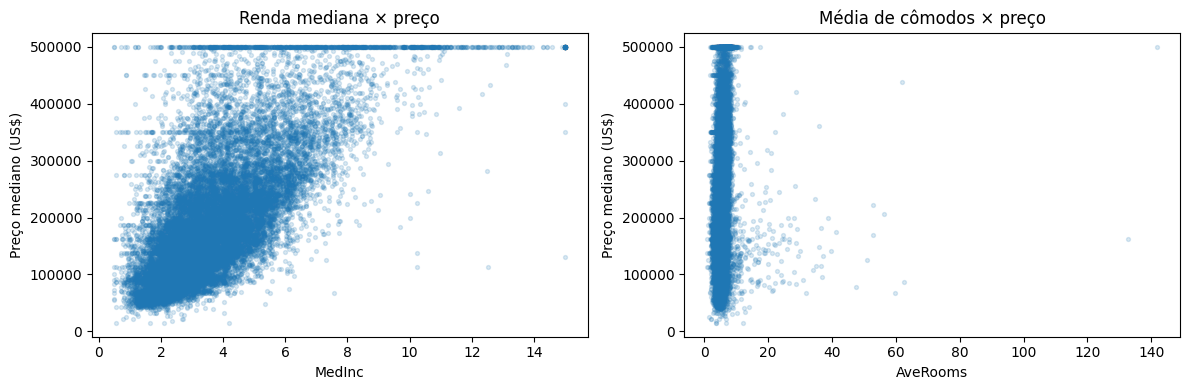

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, coluna, titulo in zip(
    axes,
    ['MedInc', 'AveRooms'],
    ['Renda mediana × preço', 'Média de cômodos × preço']
):
    ax.scatter(df[coluna], df['Preco_USD'], alpha=0.16, s=8)
    ax.set_xlabel(coluna)
    ax.set_ylabel('Preço mediano (US$)')
    ax.set_title(titulo)
plt.tight_layout()
plt.show()

## 2. Treino, validação e teste

Separei 70% para treino, 15% para validação e 15% para teste, usando uma semente fixa. Os `StandardScaler` são ajustados **somente no treino**: depois, uso os mesmos valores de média e desvio-padrão para transformar validação e teste.

In [3]:
X_treino_raw, X_temp_raw, y_treino_raw, y_temp_raw = train_test_split(
    X.to_numpy(), y.to_numpy().reshape(-1, 1),
    test_size=0.30, random_state=SEED
)
X_val_raw, X_teste_raw, y_val_raw, y_teste_raw = train_test_split(
    X_temp_raw, y_temp_raw, test_size=0.50, random_state=SEED
)

x_scaler = StandardScaler().fit(X_treino_raw)
y_scaler = StandardScaler().fit(y_treino_raw)

X_treino = torch.from_numpy(x_scaler.transform(X_treino_raw)).float()
X_val = torch.from_numpy(x_scaler.transform(X_val_raw)).float()
X_teste = torch.from_numpy(x_scaler.transform(X_teste_raw)).float()

y_treino = torch.from_numpy(y_scaler.transform(y_treino_raw)).float()
y_val = torch.from_numpy(y_scaler.transform(y_val_raw)).float()
y_teste = torch.from_numpy(y_scaler.transform(y_teste_raw)).float()

print('Treino:', X_treino.shape, y_treino.shape)
print('Validação:', X_val.shape, y_val.shape)
print('Teste:', X_teste.shape, y_teste.shape)
assert X_treino.shape[1] == 8
assert len(X_treino) + len(X_val) + len(X_teste) == 20640

Treino: torch.Size([14448, 8]) torch.Size([14448, 1])
Validação: torch.Size([3096, 8]) torch.Size([3096, 1])
Teste: torch.Size([3096, 8]) torch.Size([3096, 1])


## 3. Modelo e treinamento

Mantive a estrutura do notebook 2.6. O modelo tem oito entradas e uma saída. Uso `nn.MSELoss` como custo e `optim.SGD` para atualizar os parâmetros. Treino por 500 épocas e acompanho o erro de treino e validação.

In [4]:
model = nn.Linear(8, 1)
criterion = nn.MSELoss()
optimizer = optim.SGD(model.parameters(), lr=0.05)
n_epochs = 500

train_losses = []
val_losses = []

def train_epoch(model, optimizer, criterion, x_train, y_train):
    model.train()
    optimizer.zero_grad()
    y_pred = model(x_train)
    loss = criterion(y_pred, y_train)
    loss.backward()
    optimizer.step()

def validate_epoch(model, criterion, x, y):
    model.eval()
    with torch.no_grad():
        return criterion(model(x), y).item()

for epoch in range(n_epochs):
    train_epoch(model, optimizer, criterion, X_treino, y_treino)
    train_losses.append(validate_epoch(model, criterion, X_treino, y_treino))
    val_losses.append(validate_epoch(model, criterion, X_val, y_val))
    if (epoch + 1) % 100 == 0:
        print(f'Época {epoch + 1:3d}/{n_epochs} | treino: {train_losses[-1]:.5f} | validação: {val_losses[-1]:.5f}')

Época 100/500 | treino: 0.40541 | validação: 0.40733
Época 200/500 | treino: 0.39470 | validação: 0.40187
Época 300/500 | treino: 0.39280 | validação: 0.40284
Época 400/500 | treino: 0.39240 | validação: 0.40359
Época 500/500 | treino: 0.39229 | validação: 0.40389


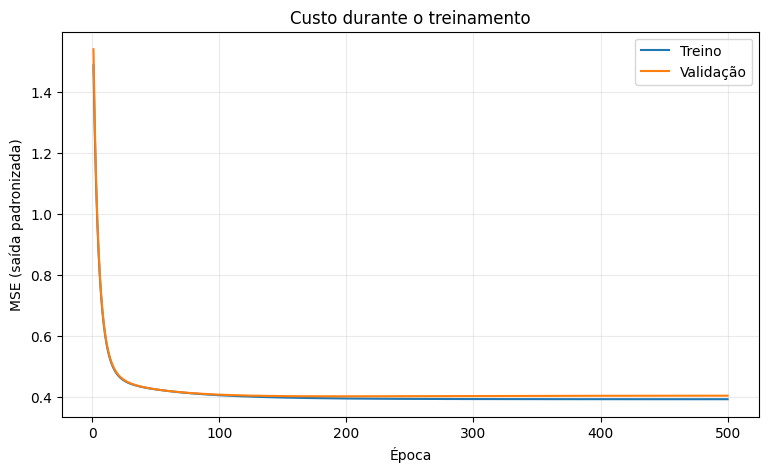

In [5]:
plt.figure(figsize=(9, 5))
plt.plot(range(1, n_epochs + 1), train_losses, label='Treino')
plt.plot(range(1, n_epochs + 1), val_losses, label='Validação')
plt.xlabel('Época')
plt.ylabel('MSE (saída padronizada)')
plt.title('Custo durante o treinamento')
plt.legend()
plt.grid(alpha=0.25)
plt.show()

## 4. Avaliação no teste e baseline

Agora avalio no **teste**, que ficou separado do treinamento. Converto as previsões para dólares e comparo com um modelo bem simples: prever sempre o preço médio do conjunto de treino.

RMSE do modelo no teste: US$ 72,422.46
RMSE do baseline:        US$ 116,708.28
Redução do RMSE:         37.9%


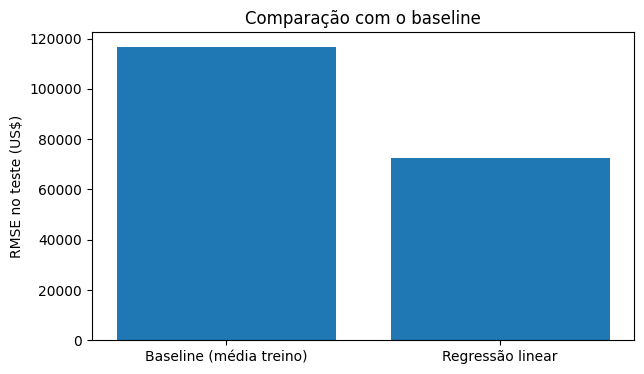

In [6]:
model.eval()
with torch.no_grad():
    pred_teste_pad = model(X_teste).numpy()

pred_teste_usd = y_scaler.inverse_transform(pred_teste_pad).ravel() * 100_000
real_teste_usd = y_teste_raw.ravel() * 100_000
media_treino_usd = y_treino_raw.mean() * 100_000
baseline_usd = np.full_like(real_teste_usd, media_treino_usd)

rmse_modelo = np.sqrt(np.mean((pred_teste_usd - real_teste_usd) ** 2))
rmse_baseline = np.sqrt(np.mean((baseline_usd - real_teste_usd) ** 2))
melhora_pct = 100 * (1 - rmse_modelo / rmse_baseline)

print(f'RMSE do modelo no teste: US$ {rmse_modelo:,.2f}')
print(f'RMSE do baseline:        US$ {rmse_baseline:,.2f}')
print(f'Redução do RMSE:         {melhora_pct:.1f}%')

plt.figure(figsize=(7, 4))
plt.bar(['Baseline (média treino)', 'Regressão linear'], [rmse_baseline, rmse_modelo])
plt.ylabel('RMSE no teste (US$)')
plt.title('Comparação com o baseline')
plt.show()

## 5. Os oito pesos aprendidos

Como todas as entradas foram padronizadas usando a mesma regra, seus coeficientes podem ser comparados na escala do modelo: cada peso indica a mudança prevista na **saída padronizada** quando a entrada aumenta um desvio-padrão, mantendo as demais constantes. Isso não prova que a variável cause a mudança no preço.

Sem padronização, comparar diretamente os valores dos pesos seria enganoso, pois as variáveis usam escalas muito diferentes (por exemplo, latitude e população).

,Variavel,Peso_padronizado
0,MedInc,0.73863
3,AveBedrms,0.25067
1,HouseAge,0.10690
4,Population,-0.00237
5,AveOccup,-0.03726
2,AveRooms,-0.22552
7,Longitude,-0.71916
6,Latitude,-0.74479


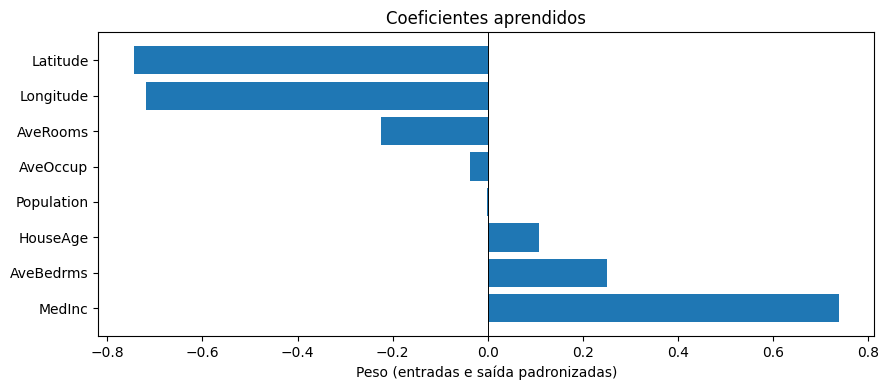

Maior coeficiente positivo: MedInc (+0.7386)
Maior coeficiente negativo: Latitude (-0.7448)


In [7]:
pesos = model.weight.detach().numpy().ravel()
coef = pd.DataFrame({'Variavel': X.columns, 'Peso_padronizado': pesos})
coef['Peso_abs'] = coef['Peso_padronizado'].abs()
coef = coef.sort_values('Peso_padronizado', ascending=False)
display(coef[['Variavel', 'Peso_padronizado']].round(5))

plt.figure(figsize=(9, 4))
plt.barh(coef['Variavel'], coef['Peso_padronizado'])
plt.axvline(0, color='black', linewidth=0.7)
plt.xlabel('Peso (entradas e saída padronizadas)')
plt.title('Coeficientes aprendidos')
plt.tight_layout()
plt.show()

maior_aumento = coef.iloc[0]
maior_reducao = coef.iloc[-1]
print(f'Maior coeficiente positivo: {maior_aumento.Variavel} ({maior_aumento.Peso_padronizado:+.4f})')
print(f'Maior coeficiente negativo: {maior_reducao.Variavel} ({maior_reducao.Peso_padronizado:+.4f})')

## 6. Conclusão

A interpretação abaixo usa os resultados realmente calculados nas células anteriores, sem colocar números antes de executar o notebook.

In [8]:
print(f'O modelo teve RMSE de US$ {rmse_modelo:,.0f} no teste, contra US$ {rmse_baseline:,.0f} do baseline.')
if rmse_modelo < rmse_baseline:
    print('Ele foi melhor do que prever sempre a média do treino, mas o erro em dólares ainda precisa ser considerado antes de usar as previsões.')
else:
    print('Ele não conseguiu superar o baseline, então esse ajuste ainda não é satisfatório.')
print(f'O maior peso positivo foi {maior_aumento.Variavel}; o mais negativo foi {maior_reducao.Variavel}.')
print('Para tentar melhorar, eu testaria regularização, tratamento de valores extremos e modelos que consigam captar relações não lineares.')
print('Também avaliaria uma separação geográfica, porque regiões próximas podem ter preços parecidos.')

O modelo teve RMSE de US$ 72,422 no teste, contra US$ 116,708 do baseline.
Ele foi melhor do que prever sempre a média do treino, mas o erro em dólares ainda precisa ser considerado antes de usar as previsões.
O maior peso positivo foi MedInc; o mais negativo foi Latitude.
Para tentar melhorar, eu testaria regularização, tratamento de valores extremos e modelos que consigam captar relações não lineares.
Também avaliaria uma separação geográfica, porque regiões próximas podem ter preços parecidos.


**Observação:** os preços do California Housing são medianas por quarteirão e a variável-alvo tem um teto no dataset. Por isso, uma regressão linear simples não representa todos os padrões possíveis.